In [2]:
%matplotlib inline
import sys
import socket
print("Hostname:", socket.gethostname())
sys.path.append('/global/homes/v/vshankar/chorus/field_mask/Smilei')
from prem import *

Hostname: login21


In [3]:
twopi = 2*np.pi
path = '/global/homes/v/vshankar/data/chorus/high_ppc/t400_amp1e-6'
pathd = '/global/homes/v/vshankar/data/chorus/high_ppc/t400_amp1e-6/dump2'
s1 = happi.Open(results_path='{}'.format(path), verbose=False)
s1d = happi.Open(results_path='{}'.format(pathd), verbose=False)

dt=s1.namelist.Main.timestep; dx=s1.namelist.Main.cell_length[0]; 
tmax =s1.namelist.Main.simulation_time
fields = ["Ex", 'Ey', 'Ez', 'Bx', 'By', 'Bz', "Rho_elec"]

ex, ey, ez, bx, by, bz, neh = [s1.Field(fields.index(f), field=f) for f in fields]
ne, pexx, peyy, pezz, nebk, pebkxx, pebkyy, pebkzz = [s1.ParticleBinning(i) for i in range(8)]

exd, eyd, ezd, bxd, byd, bzd, nehd = [s1d.Field(fields.index(f), field=f) for f in fields]
ned, pexxd, peyyd, pezzd, nebkd, pebkxxd, pebkyyd, pebkzzd = [s1d.ParticleBinning(i) for i in range(8)]

x = ey.getAxis('x'); y = ey.getAxis('y'); ts = ey.getTimesteps(); tsd = eyd.getTimesteps();lt = len(ts); 
lx = x[-1]; ly = y[-1]
print(lt, lx, ly, tmax, dt)
print(path)

**************************
B0       = 156 nT
n0_nr    = 16.91; n0b_nr=16.81; n0i_nr=0.1
de       = 2.66 km
wpe/wce  =  4.11
wpi/wce  =  0.1
lenx_cwr = 46.65; leny_cwr = 244.89
lenx_di  = 4.48; leny_di = 23.5
before resizing: box = [46.65, 244.89]
                 Lmin, Lmax, zmax = [0.5599999999999999, 0.64, 0.21]
after resizing:  box = [48.0, 256.0]
                 Lmin, Lmax, zmax = [0.5588391918010813, 0.6411608081989186, 0.2195243103942331]
cells =  [1536.0, 8192.0]
cells per patch:  6.0 8.0
**************************
**************************
B0       = 156 nT
n0_nr    = 16.91; n0b_nr=16.81; n0i_nr=0.1
de       = 2.66 km
wpe/wce  =  4.11
wpi/wce  =  0.1
lenx_cwr = 46.65; leny_cwr = 244.89
lenx_di  = 4.48; leny_di = 23.5
before resizing: box = [46.65, 244.89]
                 Lmin, Lmax, zmax = [0.5599999999999999, 0.64, 0.21]
after resizing:  box = [48.0, 256.0]
                 Lmin, Lmax, zmax = [0.5588391918010813, 0.6411608081989186, 0.2195243103942331]
cells =  [1536.0, 819

# Space plot

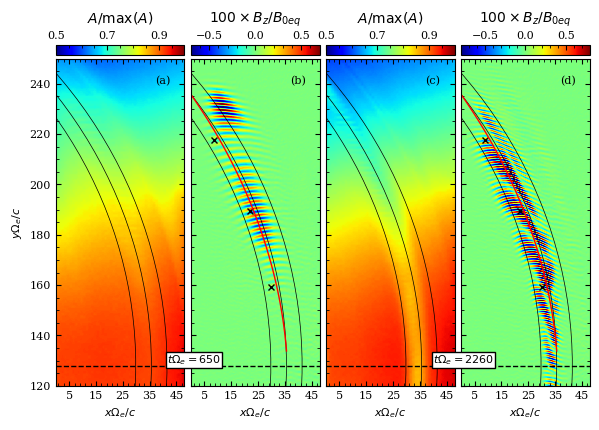

In [4]:
n0i_nr=0.34; anisot=6;box=[48,256]
plt.rc('font',size=8); plt.rc('lines',linewidth=1.0)
fig = plt.figure(figsize=(6,4.25))
l_list=[0.61, 0.62, 0.63]
gs = gridspec.GridSpec(1,4,hspace=0.1, wspace=.05) 
ax1 = fig.add_subplot(gs[0]);ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2]);ax4 = fig.add_subplot(gs[3])

tt1=65
pexxt = datat(pexx, ts,tt1); peyyt = datat(peyy,ts, tt1); net = datat(peyy,ts, tt1)
Tper  = pexxt/net*511;Tpar  = peyyt/net*511
img1  = ax1.imshow((Tper/Tpar/anisot).T, origin='lower',aspect='auto',cmap='jet',
                extent=[x[0], x[-1], y[0], y[-1]],vmin=.5,vmax=1.0)
axex(ax1); plot_fld_lines_sim(ax1,l_list); 
cbar(img1,ax1,[0, 1.01, 1.0, .03],'horizontal',ticks=[.5,.7,.9])

bzt=(datat(bz,ts,tt1)-datat(bz,ts,0))*100
img2=ax2.imshow(bzt.T,cmap='jet',origin='lower',aspect='auto',
                extent=[0,box[0],00,box[1]],vmin=-.7,vmax=.7)
axex(ax2);plot_fld_lines_sim(ax2,l_list);cbar(img2,ax2,[0, 1.01, 1.0, .03],'horizontal')

tt2=26
pexxt = datat(pexxd, tsd,tt2); peyyt = datat(peyyd,tsd, tt2); net = datat(peyyd,tsd, tt2)
Tper  = pexxt/net*511; Tpar  = peyyt/net*511
img3=ax3.imshow((Tper/Tpar/anisot).T, origin='lower',aspect='auto',cmap='jet',
                extent=[x[0], x[-1], y[0], y[-1]],vmin=.5,vmax=1.0)
axex(ax3);plot_fld_lines_sim(ax3,l_list);cbar(img3,ax3,[0, 1.01, 1.0, .03],'horizontal',ticks=[.5,.7,.9])

bzt=(datat(bzd,tsd,tt2)-datat(bzd,tsd,0))*100
img1=ax4.imshow(bzt.T,cmap='jet',origin='lower',aspect='auto',
                extent=[0,box[0],00,box[1]],vmin=-0.8,vmax=0.8)
axex(ax4);plot_fld_lines_sim(ax4,l_list);cbar(img1,ax4,[0, 1.01, 1.0, .03],'horizontal')
ax2.tick_params(axis='y', labelleft=False);ax3.tick_params(axis='y', labelleft=False)
ax4.tick_params(axis='y', labelleft=False)
ax1.set_ylabel('$y \Omega_e/c$')
ax1.text(37,240,'(a)');ax2.text(37,240,'(b)');ax3.text(37,240,'(c)');ax4.text(37,240,'(d)')
ax1.set_title('$A/\max(A)$',fontsize=10);ax2.set_title('$100\\times B_z/B_{0eq}$',fontsize=10)
ax3.set_title('$A/\max(A)$',fontsize=10);ax4.set_title('$100\\times B_z/B_{0eq}$',fontsize=10)
probe_marks(ax2,.615,[75,80,85]);probe_marks(ax4,.615,[75,80,85])
xr=np.loadtxt('ray_data/x_-20.dat')
yr=np.loadtxt('ray_data/y_-20.dat')
ax2.plot(xr,yr,'r');ax4.plot(xr,yr,'r')

fig.text(0.33,0.16,f'$t\Omega_e={tt1*10}$', ha='center', va='center',
    bbox=dict( boxstyle='square,pad=0.1',facecolor='white',edgecolor='black',linewidth=1.0))
fig.text(0.78,0.16,f'$t\Omega_e={(200+tt2)*10}$', ha='center', va='center',
    bbox=dict( boxstyle='square,pad=0.1',facecolor='white',edgecolor='black',linewidth=1.0))

plt.subplots_adjust(left=.10,right=.99,top=.870,bottom=0.10)
plt.savefig(f'/global/homes/v/vshankar/data/figs/chorus_paper/space.pdf')
plt.show()

# Spect

/global/homes/v/vshankar/data/chorus/high_ppc/t400_amp1e-6


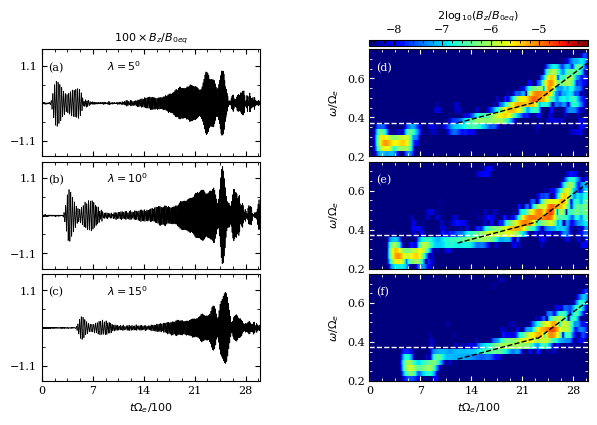

In [6]:
print(path)
from scipy.signal import hilbert
fig = plt.figure(figsize=(6,4.25));plt.rc('font',size=8);plt.rc('lines',linewidth=.7)
gs = gridspec.GridSpec(3,2,hspace=0.05, wspace=.5)
nperseg, nleap = 512, 16
noverlap = nperseg - nleap
field = 'Bz'
tmax = 3000
Nsamping=20
fs=int(1/(Nsamping*dt))
lda=['$\lambda=5^0$', '$\lambda=10^0$', '$\lambda=15^0$']
A=['(a)','(b)','(c)']
B=['(d)','(e)','(f)']
intc=[-.16,-.2,-.23];  
intc1=[.25,.21,.19];
datam = np.load(f'{path}/probe_{field}_12_{tmax}.npy')
dmx= max(datam*100); dmn= min(datam*100)
for i in range(3):
    # ---- Time series ----
    ax1 = fig.add_subplot(gs[i,0])
    data = np.load(f'{path}/probe_{field}_{14-2*i}_{tmax}.npy') 
    tt=np.linspace(0,tmax,len(data))
    # ax11=ax1.twinx() if i==0 else None
    # ax11.plot(tt/100, np.log(np.abs(hilbert(data)))) if i==0 else None
    # lfit(ax11,800,1200,0.0066,-15.3,'k',np.log(np.abs(hilbert(data)))) if i==0 else None
    # lfit(ax11,1200,1600,0.005,-13.6,'k',np.log(np.abs(hilbert(data)))) if i==0 else None
    # lfit(ax11,1600,2200,0.004,-13.,'k',np.log(np.abs(hilbert(data)))) if i==0 else None
    ax1.plot(tt/100, data*100, 'k', lw=0.5)
    # ax1.set_ylabel(f'$100 \\times B_z/B_{{0 eq}}$')
    ax1.set_title(f'$100 \\times B_z/B_{{0 eq}}$', fontsize=8) if i==0 else None
    ax1.text(.03,.8,f'{A[i]}', transform=ax1.transAxes)
    pltmd(ax1,'k')
    ax1.set_xlim(0,30)
    ax1.set_ylim(1.1*dmn,1.1*dmx)
    ax1.set_yticks([-round(0.75*dmx,1), round(0.75*dmx,1)])
    ax1.set_xticks([0, 7, 14, 21, 28])
    # ax1.axvline(xi/2.3/100,ls='--',color='k') and ax1.axvline(xf/2.3/100,ls='--',color='k') if i==1 else None
    ax1.tick_params(axis='x', labelbottom=False) if i in range(2) else ax1.set_xlabel('$t\Omega_e/100$')
    ax2 = fig.add_subplot(gs[i,1])
    freq, t, spec = signal.stft( data, 2.3, window=('tukey', 1), nperseg=nperseg, noverlap=noverlap)
    spec_log = np.log10(abs(spec)**2)
    img = ax2.imshow(spec_log,cmap='jet', aspect='auto', origin='lower', interpolation='none',
                     extent=[0, 30, freq[0]*twopi, freq[-1]*twopi],vmin=-8.5, vmax=-4)
    ax2.set_ylim(0.2, 0.75)
    ax2.set_xlim(0, 30)
    ax2.text(.03, .8, f'{B[i]}',color='w', transform=ax2.transAxes)
    ax1.text(.3, .8, f'{lda[i]}',color='k', transform=ax1.transAxes)
    ax2.axhline(y=0.372,ls='--',color='w',lw=1.0)
    lfit(ax2,2300,3000,0.00028,intc[i],'k',data)
    lfit(ax2,1200,2300,0.0001,intc1[i],'k',data)
    pltmd(ax2,'w')
    ax2.set_ylabel(f'$\\omega/\\Omega_{{e}}$')
    ax2.set_xticks([0, 7, 14, 21, 28])
    cbar(img,ax2,[0, 1.03, 1.0, .06],'horizontal',ticks=[-8.0,-7.0,-6.0,-5.0],label=r'$2\mathrm{log}_{10}(B_z/B_{0 eq})$') if i==0 else None
    ax2.tick_params(axis='x', labelbottom=False) if i in range(2) else ax2.set_xlabel('$t\Omega_e/100$')
plt.subplots_adjust(left=.08,right=.99,top=.88,bottom=0.10,hspace=0.3,wspace=.89)
plt.savefig('/global/homes/v/vshankar/data/figs/chorus_paper/spect.pdf')
plt.show()

# Spect_comp

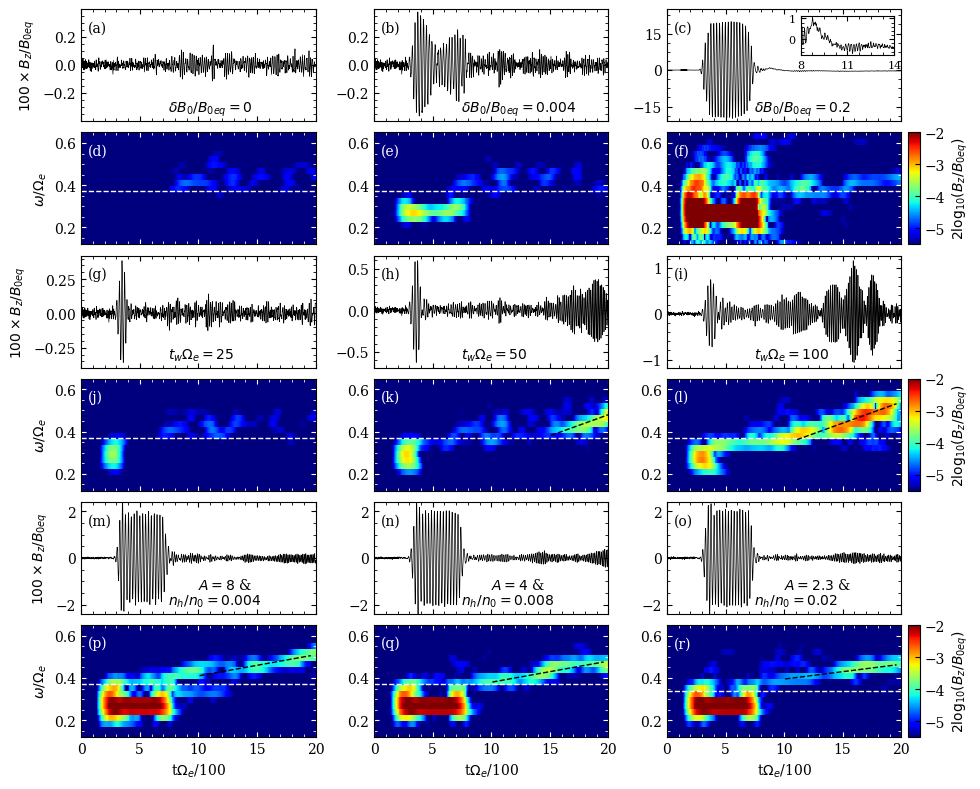

In [7]:
fig = plt.figure(figsize=(10,8.0));plt.rc('font',size=10);plt.rc('lines',linewidth=.7)
gs = gridspec.GridSpec(6,3, hspace=0.1,wspace=.25)
nperseg, nleap = 512, 16; noverlap = nperseg - nleap; field = 'Bz'; tmax = 2000
inpath='/global/homes/v/vshankar/data/chorus'
pathd=[f'{inpath}/full_ant/ans_6woant',
      f'{inpath}/d_perl/ans_6_nh_.006_amp5e-7',
      f'{inpath}/d_perl/ans_6_nh_.006_amp5e-5',
      f'{inpath}/d_perl/t_25_ans_6_nh_.006_amp1e-6',
      f'{inpath}/d_perl/t_50_ans_6_nh_.006_amp1e-6',
      f'{inpath}/d_perl/t_100_ans_6_nh_.006_amp1e-6',
      f'{inpath}/den/den_.004_ans_8',
      f'{inpath}/den/den_.008_ans_4',
      f'{inpath}/d_perl/ans_2.3_nh_.02']
A = ['(a)','(b)','(c)','(g)','(h)','(i)','(m)','(n)','(o)']
B = ['(d)','(e)','(f)','(j)','(k)','(l)','(p)','(q)','(r)']
lbl=[r'$\delta B_0/B_{0 eq}=0$', r'$\delta B_0/B_{0 eq}=0.004$', r'$\delta B_0/B_{0 eq}=0.2$', 
     r'$t_w\Omega_e=25$', r'$t_w\Omega_e=50$', r'$t_w\Omega_e=100$',
     r'$n_h/n_0=0.004$', r'$n_h/n_0=0.008$', r'$n_h/n_0=0.02$']

lbla=[None,None,None,None,None,None,r'$A=8$ &', r'$A=4$ &', r'$A=2.3$ &']

for i, p in enumerate(pathd):
    if pathd.index(p) < 3:
        j0, j1 = 0, 1
    elif pathd.index(p) < 6:
        j0, j1,i = 2, 3, i-3
    else:
            j0, j1,i = 4, 5, i-6

    ax1 = fig.add_subplot(gs[j0,i])
    if pathd.index(p) in range(6):
        data = np.load(f'{p}/probe_{field}_{12}_{tmax}.npy')
    else:
        data = np.load(f'{p}/probe_{field}_{2}_{tmax}.npy')
    tt=np.linspace(0,tmax,len(data))/100
    ax1.plot(tt, 100*data, 'k', lw=0.5)
    ax1.set_ylabel(f'$100 \\times B_z/B_{{0 eq}}$') if i==0 else None
    ax1.text(.37,.08,f'{lbl[pathd.index(p)]}', transform=ax1.transAxes)
    if j0==4:
        ax1.text(.5,.22,f'{lbla[pathd.index(p)]}', transform=ax1.transAxes) 
    pltmd(ax1,'k');ax1.set_xlim(0,20)
    if i==2 and j0==0:
        ax1.set_ylim(-21,25) and ax1.set_yticks([-15,0,15])

    elif i in range(2) and j0==0:
        ax1.set_ylim(-.4,.4) and ax1.set_yticks([-.2,0,.2])
    elif i in range(3) and j0==4:
               ax1.set_ylim(-2.4,2.4) and ax1.set_yticks([-2.0,0,2.0]) 

    if i==2 and j0==0:
        axins = inset_axes(ax1, width="40%", height="35%", loc="upper right")
        axins.plot(tt[int(2.3*800):int(2.3*1800)], 100*data[int(2.3*800):int(2.3*1800)], 'k', lw=0.5)
        # axins.axhline(0,color='r',ls='--')
        axins.set_xlim(int(8),int(14))
        pltmd(axins,'k')
        # axins.tick_params(axis='x', labelbottom=False)
        # axins.tick_params(axis='y', labelleft=False)
        axins.set_xticks([8,11,14])
        axins.tick_params(axis='both', labelsize=8)
        
    ax1.text(.03,.8,f'{A[pathd.index(p)]}', transform=ax1.transAxes) 
    ax1.tick_params(axis='x', labelbottom=False)
    ax2 = fig.add_subplot(gs[j1,i])
    freq, t, spec = signal.spectrogram( data, 2.3, window=('tukey', 1), nperseg=nperseg, noverlap=noverlap)
    spec_log = np.log10(spec)
    img = ax2.imshow(spec_log,cmap='jet', aspect='auto', origin='lower', interpolation='none',
                    extent=[0, 20, freq[0]*twopi, freq[-1]*twopi],vmin=-5.5, vmax=-2)
    ax2.set_ylim(0.12, 0.65)
    ax2.set_xlim(t[0], t[-1])
    ax2.text(.03,.8,f'{B[pathd.index(p)]}',color='w', transform=ax2.transAxes)
    ax2.set_xlim(0,20);pltmd(ax2,'w')
    ax2.axhline(y=.34,ls='--',color='w',lw=1.0) if j1==5 and i==2 else ax2.axhline(y=0.372,ls='--',color='w',lw=1.0)
    ax2.set_ylabel(f'$\omega/\\Omega_{{e}}$') if i==0 else None
    cbar(img,ax2,[1.03, 0.0, .05, 1.0],'vertical',ticks=[-5.0,-4.0,-3,-2],label=r'$2\mathrm{log}_{10}(B_z/B_{0 eq})$') if i==2 else None
    ax2.set_xlabel(r't$\Omega_{e}$/100') if j1==5 else ax2.tick_params(axis='x', labelbottom=False)
    if j1==3 and i==1:
       lfit(ax2, 1500, 2000, 0.0002, 0.08, 'k', data)
    elif j1==3 and i==2:
         lfit(ax2, 1100, 1950, 0.0002, 0.14, 'k', data)
    elif j1==5 and i==0:
         lfit(ax2, 1000, 1950, 0.0001, 0.31, 'k', data)
    elif j1==5 and i==1:
             lfit(ax2, 1000, 1950, 0.0001, 0.28, 'k', data)
    elif j1==5 and i==2:
             lfit(ax2, 1000, 1950, 0.00007, 0.325, 'k', data)
    # ax2.text(.37,.08,f'{lbl[pathd.index(p)]}',fontsize=12,color='w', transform=ax2.transAxes)
    # if j1==5:
    #     ax2.text(.5,.22,f'{lbla[pathd.index(p)]}',fontsize=12,color='w', transform=ax2.transAxes) 
plt.subplots_adjust(left=.09,right=.91,top=.98,bottom=0.07,hspace=0.06,wspace=0.05)
plt.savefig('/global/homes/v/vshankar/data/figs/chorus_paper/spect_comp.pdf')
plt.show()

# Self-generated case

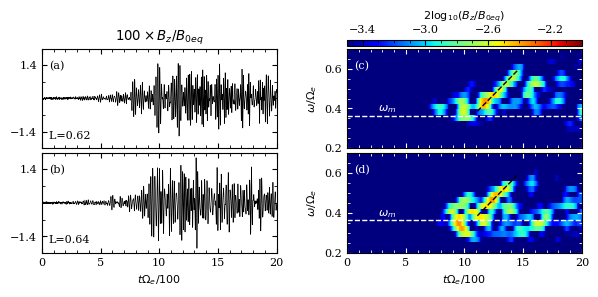

In [8]:
fig = plt.figure(figsize=(6,3.0));plt.rc('font',size=8);plt.rc('lines',linewidth=.7)
gs = gridspec.GridSpec(2,2,hspace=0.05, wspace=.3)
nperseg, nleap = 512, 16; noverlap = nperseg - nleap
tmax = 2000; Nsamping=20; fs=int(1/(Nsamping*dt))
lda=['L=0.62 ', 'L=0.64']
A=['(a)','(b)',]; B=['(c)','(d)']
datam = np.load(f'/global/u2/v/vshankar/psc/data/chorus/wo_ant/ans_3.5/probe_Bz_32_2000.npy')
dmx= max(datam*100); dmn= min(datam*100)
for i,d in zip(range(2),[12,32]):
    # ---- Time series ----
    ax1 = fig.add_subplot(gs[i,0])
    data = np.load(f'/global/u2/v/vshankar/psc/data/chorus/wo_ant/ans_3.5/probe_Bz_{d}_{tmax}.npy') 
    tt=np.linspace(0,tmax,len(data))
    ax1.plot(tt/100, data*100, 'k', lw=0.5)
    # ax11=ax1.twinx() if i==0 else None
    # ax11.plot(tt/100, np.log(np.abs(hilbert(data)))) if i==0 else None
    # lfit(ax11,200,1000,0.009,-13.3,'k',np.log(np.abs(hilbert(data)))) if i==0 else None
    # ax1.set_ylabel(f'$100 \\times B_z/B_{{0 eq}}$')
    ax1.set_title(f'$100 \\times B_z/B_{{0 eq}}$') if i==0 else None
    ax1.text(.03,.8,f'{A[i]}', transform=ax1.transAxes)
    pltmd(ax1,'k')
    ax1.set_xlim(0,20)
    ax1.set_ylim(1.1*dmn,1.1*dmx)
    ax1.set_yticks([-round(0.75*dmx,1), round(0.75*dmx,1)])
    ax1.set_xticks([0, 5, 10, 15, 20])
    ax1.tick_params(axis='x', labelbottom=False) if i in range(1) else ax1.set_xlabel('$t\Omega_e/100$')
    ax2 = fig.add_subplot(gs[i,1])
    freq, t, spec = signal.spectrogram( data, 2.3, window=('tukey', 1), nperseg=nperseg, noverlap=noverlap)
    spec_log = np.log10(spec)
    img = ax2.imshow(spec_log,cmap='jet', aspect='auto', origin='lower', interpolation='none',
                     extent=[0, 20, freq[0]*twopi, freq[-1]*twopi],vmin=-3.5, vmax=-2)
    ax2.set_ylim(0.2, 0.70)
    ax2.set_xlim(0, 20)
    ax2.text(.03, .8, f'{B[i]}',color='w', transform=ax2.transAxes)
    ax1.text(.03, .1, f'{lda[i]}',color='k', transform=ax1.transAxes)
    ax2.text(.13, .374, '$\omega_m$',color='w', transform=ax2.transAxes)
    ax2.axhline(y=0.364,ls='--',color='w',lw=1.0)
    lfit(ax2, 1100, 1450, 0.0006, -0.28, 'k', data)
    # lfit(ax2, 920, 1070, -0.0006, 0.92,'k', data) if i==1 else None
    # lfit(ax2,950,1150,-0.0006,1.05,'k',data) if i==1 else None
    pltmd(ax2,'w')
    ax2.set_ylabel(f'$\\omega/\\Omega_{{e}}$')
    ax2.set_xticks([0, 5, 10, 15, 20])
    cbar(img,ax2,[0, 1.03, 1.0, .06],'horizontal',ticks=[-3.4,-3.0,-2.6, -2.2],label=r'$2\mathrm{log}_{10}(B_z/B_{0 eq})$') if i==0 else None
    ax2.tick_params(axis='x', labelbottom=False) if i in range(1) else ax2.set_xlabel('$t\Omega_e/100$')
plt.subplots_adjust(left=.08,right=.98,top=.83,bottom=0.15,hspace=0.3,wspace=.39)
plt.savefig('/global/homes/v/vshankar/data/figs/chorus_paper/self_spect.pdf')
plt.show()

# Particle analysis

In [12]:
# t0 = time.time()
ti = 0; dlx, dly = 0.1, .1
l = 0.615; lda = 10; df = 46; tstp=[0]; deltp=0.1
path='/global/homes/v/vshankar/data/chorus/high_ppc/t400_amp1e-6'
path0='/global/homes/v/vshankar/data/chorus/high_ppc/t400_amp1e-6'
paths='/global/homes/v/vshankar/data/chorus/pdata/high_ppc/t400_amp1e-6'
xd,yd = dip_pos(l,lda)
print("xd, yd =", xd, yd)
fe = h5py.File(f'{path}/TrackParticlesDisordered_elec.h5', 'r')
fe0 = h5py.File(f'{path0}/TrackParticlesDisordered_elec.h5', 'r')
# window_size = 100; weights = np.ones(window_size)/window_size
for tt in tstp:
    print(tt)
    Bx, By, Bz, px, py, pz, x, y = datap(tt, fe, df)
    Bx0, By0, Bz0, px0, py0, pz0, x0, y0 = datap(ti, fe0, df)
    B0x, B0y = mag_b(x, y)
    B0x0, B0y0 = mag_b(x0, y0)
    B0z = np.zeros_like(B0x)
    B0z0 = np.zeros_like(B0x0)
    # ---------------- Compute quantities only in spatial mask ----------------
    maskp = (abs(y-yd) < dly) & (abs(x-xd) < dlx)
    maskp0 = (abs(y0-yd) < dly) & (abs(x0-xd) < dlx)
    theta_p, p_para_mag_p, p_perp_mag_p, gamma_p = theta_com(B0x[maskp], B0y[maskp], B0z[maskp], Bx[maskp], By[maskp], Bz[maskp], px[maskp], py[maskp], pz[maskp])
    theta0_p, p_para_mag0_p, p_perp_mag0_p, gamma0_p = theta_com(B0x0[maskp0], B0y0[maskp0], B0z0[maskp0], Bx0[maskp0], By0[maskp0], Bz0[maskp0], px0[maskp0], py0[maskp0], pz0[maskp0])
# surface data
    Hi, xedges, yedges = np.histogram2d(p_para_mag_p, p_perp_mag_p, bins=400, density=True)
    H0, xedges0, yedges0 = np.histogram2d(p_para_mag0_p, p_perp_mag0_p, bins=400, density=True)
    dH=(Hi-H0)/H0.max()
    H = gaussian_filter(dH, sigma=1.0)
    xcenters = (xedges[:-1] + xedges[1:]) / 2
    ycenters = (yedges[:-1] + yedges[1:]) / 2
    X, Y = np.meshgrid(xcenters, ycenters)
    Z = H.T  # transpose to match meshgrid
    np.savetxt(f'{paths}/X_{tt}.dat', X)
    np.savetxt(f'{paths}/Y_{tt}.dat', Y)
    np.savetxt(f'{paths}/Z_{tt}.dat', Z)
    
    # phase space and momentum
    for pp in np.arange(0,1,deltp):
        p_perp_min, p_perp_max = round(pp, 2), round((pp+deltp), 2)
        mask = (p_perp_mag_p > p_perp_min) & (p_perp_mag_p < p_perp_max)
        mask0 = (p_perp_mag0_p > p_perp_min) & (p_perp_mag0_p < p_perp_max)
        theta_m = theta_p[mask]
        p_para_mag_m = p_para_mag_p[mask]
        p_perp_mag_m = p_perp_mag_p[mask]
        gamma_m = gamma_p[mask]
        theta0_m = theta0_p[mask0]
        p_para_mag0_m = p_para_mag0_p[mask0]
        p_perp_mag0_m = p_perp_mag0_p[mask0]
        # Phase space v_perp vs v_para
        psd0, pxedges0, pyedges0 = np.histogram2d(p_perp_mag0_p, p_para_mag0_p, bins=400, density=True)
        psd, pxedges, pyedges = np.histogram2d(p_perp_mag_p, p_para_mag_p, bins=400, density=True)
        pextent0 = [pyedges0[0], pyedges0[-1], pxedges0[0], pxedges0[-1]]
        np.savetxt(f'{paths}/psd_{tt}_{p_perp_min}_{p_perp_max}.dat', psd/np.max(psd))
        ph0, xe0 = np.histogram(p_para_mag0_p, bins=400, density=True)
        ph, xe = np.histogram(p_para_mag_p, bins=400, density=True)
        centers = (xe[1:] + xe[:-1]) / 2.0
        centers0 = (xe0[1:] + xe0[:-1]) / 2.0
        np.savetxt(f'{paths}/centers_{tt}_{p_perp_min}_{p_perp_max}p.dat',centers)
        np.savetxt(f'{paths}/centers_{ti}_{p_perp_min}_{p_perp_max}p.dat',centers0)
        np.savetxt(f'{paths}/ph_{tt}_{p_perp_min}_{p_perp_max}p.dat',ph)
        np.savetxt(f'{paths}/ph_{ti}_{p_perp_min}_{p_perp_max}p.dat',ph0)

        theta0_m = theta0_m % (2*np.pi)
        theta_m = theta_m % (2*np.pi)
        H0, xedges0, yedges0 = np.histogram2d(theta0_m, p_para_mag0_m, bins=400, density=True, range=[[0,2*np.pi],[-.6,.6]])
        Hp, xedges, yedges = np.histogram2d(theta_m, p_para_mag_m, bins=400, density=True, range=[[0,2*np.pi],[-.6,.6]])
        extent0 = [xedges0[0], xedges0[-1], yedges0[0], yedges0[-1]]
        H = ((Hp-H0)/np.max(H0))
        np.savetxt(f'{paths}/h_{tt}_{p_perp_min}_{p_perp_max}.dat',H)
        np.savetxt(f'{paths}/xedges0_{tt}_{p_perp_min}_{p_perp_max}.dat',xedges0)
        np.savetxt(f'{paths}/yedges0_{tt}_{p_perp_min}_{p_perp_max}.dat',yedges0)
        np.savetxt(f'{paths}/yedges_{tt}_{p_perp_min}_{p_perp_max}.dat',yedges)
        np.savetxt(f'{paths}/xedges_{tt}_{p_perp_min}_{p_perp_max}.dat',xedges)
print(max(gamma_p))

xd, yd = 21.933265591169036 189.3231073001561
0
2.2920583280993223


/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/site-packages/numpy/lib/histograms.py:1067: RuntimeWarning: invalid value encountered in divide
  hist /= s


In [8]:
# !ls /scratch2/10567/vshankar786/pdata/data
# !rm -rf /scratch2/10567/vshankar786/pdata/data/*

[650, 2260]


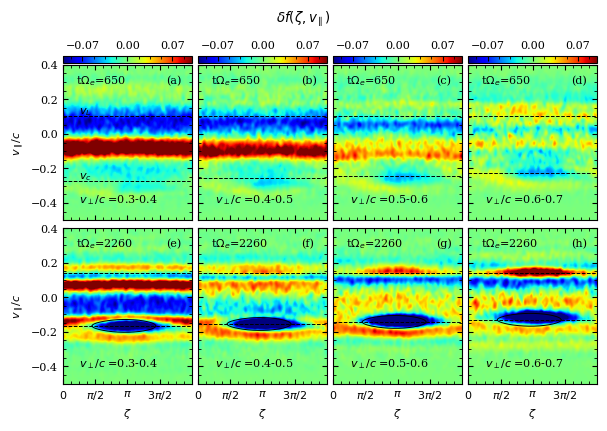

In [11]:
# paths='/global/homes/v/vshankar/data/chorus/tacc_data/pdata/data/paper'
paths='/global/homes/v/vshankar/data/chorus/pdata/high_ppc/t400_amp1e-6/0.615_10'
tstp=[650,2260]
from matplotlib.ticker import AutoMinorLocator
from matplotlib.gridspec import GridSpec
plt.rc('font', size=8)
fig = plt.figure(figsize=(6,4.25))
gs = GridSpec(2, 4, figure=fig)
print(tstp)
# gs = gridspec.GridSpec(2, 5, hspace=0.1)
# idxm=gs.nrows*gs.ncols
ax1 = fig.add_subplot(gs[0, 0]);ax2 = fig.add_subplot(gs[0, 1]);ax3 = fig.add_subplot(gs[0, 2]);ax4 = fig.add_subplot(gs[0, 3]);
ax5 = fig.add_subplot(gs[1, 0]);ax6 = fig.add_subplot(gs[1, 1]);ax7 = fig.add_subplot(gs[1, 2]);ax8 = fig.add_subplot(gs[1, 3])
axes=[ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8]
A=['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)']
for tt in tstp:
    (w,kpar)=(0.256, 2.45) if tt==tstp[0] else (0.42,.89*disp(.40,0))
    for pp in np.arange(0.3,.7,.1):
        # axt = fig.add_subplot(gs[idx])
        idx = int(round(pp*10-3)) if tt==tstp[0] else int(round(pp*10-3))+4
        p_perp_min, p_perp_max = round(pp, 2), round((pp+.1), 2)
        # gamma=np.max(np.sqrt(1.0+p_perp_min**2+p_para_mag_m**2))
        gamma=np.max(np.sqrt(1.0+p_perp_max**2+.15**2))
        vc=(w-1/gamma)/kpar; vc1=(1+w*gamma)/kpar; vl=w/kpar
        f=np.load(f'{paths}/h_{tt}_{p_perp_min}_{p_perp_max}.npy')
        xedges0=np.load(f'{paths}/xedges0_{tt}_{p_perp_min}_{p_perp_max}.npy')
        yedges0=np.load(f'{paths}/yedges0_{tt}_{p_perp_min}_{p_perp_max}.npy')
        f = gaussian_filter(f, sigma=4.0)
        extent0 = [xedges0[0], xedges0[-1], yedges0[0], yedges0[-1]]
        im=axes[idx].imshow(f.T,origin='lower',extent=extent0, aspect='auto',
                   interpolation='spline16',cmap='jet', vmin=-0.1, vmax=0.1)
        if idx<4:
            cbar(im,axes[idx],[0, 1.01, 1.0, .05],'horizontal',ticks=[-.07,0,.07])#,label='$\delta f (\zeta, v_\parallel)/f_0$')
        if idx in [0,4]:
            axes[idx].set_ylabel(r'$v_\parallel/c$')
        axes[idx].set_xticks([0, np.pi/2, np.pi, 3*np.pi/2])
        if idx>3:
            axes[idx].set_xlabel(r'$\zeta$')
            axes[idx].set_xticklabels([r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$" ])
        if idx in [0,1,2,3]:
            axes[idx].tick_params(axis='x', labelbottom=False)
        if idx in [1,2,3,5,6,7]:
            axes[idx].tick_params(axis='y', labelleft=False)
        axes[idx].text(.8,-.4,r'$v_{\perp}/c$ =%s-%s'% (p_perp_min, p_perp_max))
        axes[idx].set_ylim(-.5,.4)
        axes[idx].minorticks_on()
        axes[idx].tick_params(axis='both', which='both', direction='in', top=True, right=True)
        # axes[idx].axhline(0, linestyle='--',color='k')
        if idx==0:
            axes[0].text(.8,vc+.01,'$v_c$')
            axes[0].text(.8,vl+.01,'$v_L$')
        axes[idx].axhline(vc, linestyle='--',color='k')
        island(axes[idx],-0.11,.09,disp(.40,0),.45*np.pi,vc,'k') if idx in range(4,8) else None
        axes[idx].axhline(vl, linestyle='--',color='k')
        axes[idx].text(.8,.88, f'{A[idx]}', transform=axes[idx].transAxes)
        axes[idx].text(.1,.88,f't$\\Omega_{{e}}$={tt}', transform=axes[idx].transAxes) #if idx in [0,4] else None
        plt.suptitle('$\delta f (\zeta, v_\parallel)$')
    # axes[idx].axhline(vc1, linestyle='--',color='k')
plt.subplots_adjust(left=.10, right=.99, top=.850, bottom=.1, hspace=.05, wspace=.05)
plt.savefig(f'/global/homes/v/vshankar/data/figs/chorus_paper/phase_space.pdf')

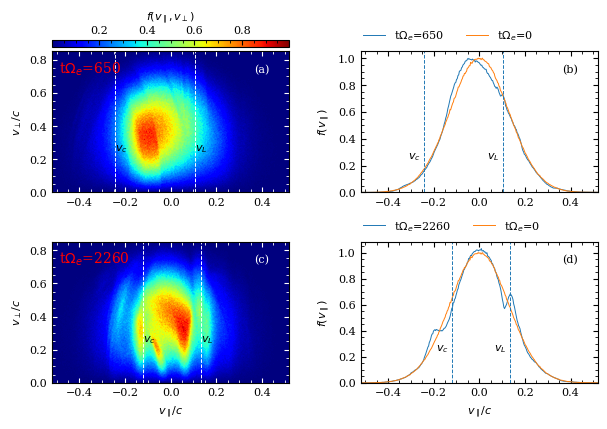

In [10]:
fig = plt.figure(figsize=(6,4.25)); ti=0
pp_min, pp_max = '0.4','0.5'
for ta, i in zip(tstp,[1,3]):
    (w,kpar)=(0.256, 2.45) if ta==tstp[0] else (0.45,.89*disp(.45,0))
    gamma=np.max(np.sqrt(1.0+.6**2+.15**2))
    vc=(w-1/gamma)/kpar; vc1=(1+w*gamma)/kpar; vl=w/kpar
    psd=np.load(f'{paths}/psd_{ta}_{pp_min}_{pp_max}.npy')
    centers=np.load(f'{paths}/centers_{ta}_{pp_min}_{pp_max}.npy')
    centers0=np.load(f'{paths}/centers_{ti}_{pp_min}_{pp_max}.npy')
    ph=np.load(f'{paths}/phpn_{ta}_{pp_min}_{pp_max}m.npy')
    ph0=np.load(f'{paths}/phpn_{ti}_{pp_min}_{pp_max}m.npy')
    pextent0 = np.load(f'{paths}/pextent0_{ta}_{pp_min}_{pp_max}.npy')
    ax = fig.add_subplot(2,2,i)
    im=ax.imshow(psd, origin='lower', extent=pextent0, aspect='auto',
               interpolation='spline16', cmap='jet')
    
    cbar(im,ax,[0, 1.03, 1.0, .05],'horizontal', ticks=[.2,.4,.6,.8],label='$f(v_\parallel,v_\perp)$') if i==1 else None
    pltmd(ax,'w')
    ax.set_xlabel(r'$v_\parallel/c$') if i==3 else None
    ax.set_ylabel(r'$v_\perp/c$')
    ax.set_xlim(-.52,.52)
    ax.set_ylim(0,.85)
    ax.axvline(vc, linestyle='--',color='w')
    ax.axvline(vl, linestyle='--',color='w')
    ax.text(vc,0.25,'$v_c$',color='k') 
    ax.text(vl,0.25,'$v_L$',color='k')
    ax.text(.03,.85,f't$\\Omega_{{e}}$={ta}', color='r', fontsize='10', transform=ax.transAxes)
    ax.text(.85,.85,'(c)',color='w', transform=ax.transAxes) if i==3 else ax.text(.85,.85,'(a)',color='w',transform=ax.transAxes)
    ax = fig.add_subplot(2,2,i+1)
    ax.plot(centers, ph/max(ph0), label=f't$\\Omega_{{e}}$={ta}')
    ax.plot(centers0, ph0/max(ph0), label=f't$\\Omega_{{e}}$={ti}')
    ax.axvline(vc, linestyle='--')
    ax.axvline(vl, linestyle='--')
    # plt.axvline(0.33, linestyle=':')
    ax.set_xlim(-.6,.6)
    ax.text(vc-0.07,0.25,'$v_c$') 
    ax.text(vl-0.07,0.25,'$v_L$')
    
    ax.set_xlabel(r'$v_\parallel / c$') if i==3 else None
    ax.set_ylabel(r'$f(v_\parallel)$')
    ax.legend(loc='upper left', ncol=2,borderpad=.01,labelspacing=.01,
               frameon=False,bbox_to_anchor=(-0.015, 1.2))
    ax.text(.85,.85,'(d)', transform=ax.transAxes) if i==3 else ax.text(.85,.85,'(b)', transform=ax.transAxes)
    ax.set_ylim(0,)
    ax.set_xlim(-.52, .52)
    pltmd(ax,'k')
plt.subplots_adjust(left=.08, right=.99, top=.880, bottom=.10, hspace=.35, wspace=.3)
plt.savefig(f'/global/homes/v/vshankar/data/figs/chorus_paper/dist.pdf')

Jb= -2.9981635355245455 /J0
Je= -4.28925243495439 /J0


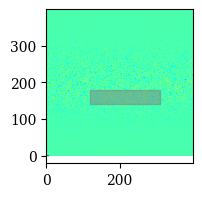

In [ ]:
%matplotlib inline
from prem import *
pp_min, pp_max = '0.4','0.5'
tt=30
plt.figure(figsize=(6,2))
f=np.loadtxt(f'{paths}/h_{tt}_{pp_min}_{pp_max}.dat')
xedges=np.loadtxt(f'{paths}/xedges_{tt}_{pp_min}_{pp_max}.dat')
xedges0=np.loadtxt(f'{paths}/xedges0_{tt}_{pp_min}_{pp_max}.dat')
yedges=np.loadtxt(f'{paths}/yedges_{tt}_{pp_min}_{pp_max}.dat')
yedges0=np.loadtxt(f'{paths}/yedges0_{tt}_{pp_min}_{pp_max}.dat')
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2
sin_zeta=np.sin(xcenters)
cos_zeta=np.cos(xcenters)
x0,y0,w,h=120,140,190,40
# print('Jb=',0.3**2*sum(sum(cos_zeta[x0:(x0+w),None]*f[x0:(x0+w),y0:(y0+h)])),'/J0')
# print('Je=',0.3**2*sum(sum(sin_zeta[x0:(x0+w),None]*f[x0:(x0+w),y0:(y0+h)])),'/J0')
print('Jb=',.4**2*sum(sum(cos_zeta[:,None]*f[:,:])),'/J0')
print('Je=',.4**2*sum(sum(sin_zeta[:,None]*f[:,:])),'/J0')
plt.imshow(f[:,:].T,origin='lower',cmap='jet')
rect(plt.gca(),x0,y0,w,h)
plt.plot(xcenters,sin_zeta)
plt.show()

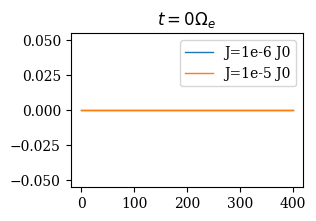

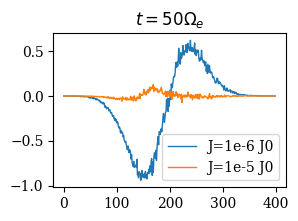

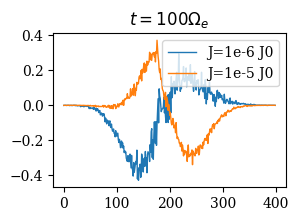

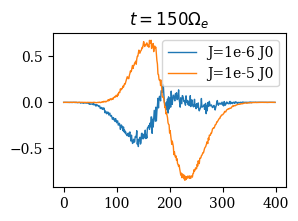

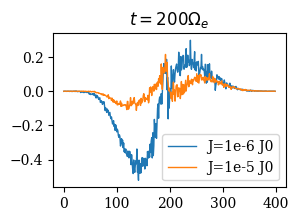

...

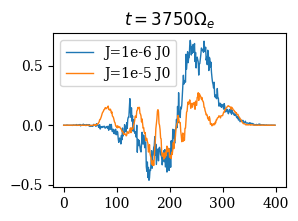

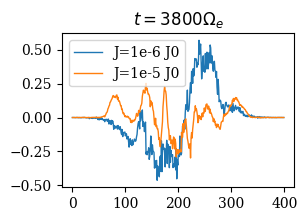

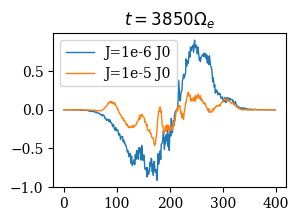

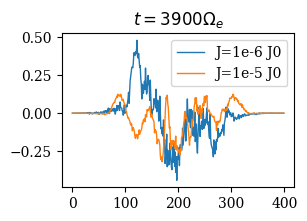

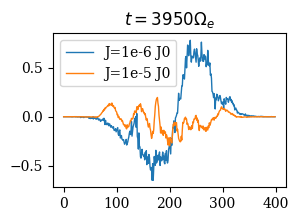

In [105]:
pp_min='0.4'; pp_max='0.5'
phstd=[];phstd1=[];psdstd=[];psdstd1=[]
for tt in range(0,4000,50):
    plt.figure(figsize=(3,2))
    # print(tt)
    ph=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/ph_{tt}_{pp_min}_{pp_max}.dat')
    ph0=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/ph_{0}_{pp_min}_{pp_max}.dat')
    ph1=np.load(f'/scratch2/10567/vshankar786/pdata/1_wave_injection/ph_{tt}_{pp_min}_{pp_max}.npy')
    ph10=np.load(f'/scratch2/10567/vshankar786/pdata/1_wave_injection/ph_{0}_{pp_min}_{pp_max}.npy')
    
    psd=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/psd_{tt}_{pp_min}_{pp_max}.dat')
    psd0=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/psd_{0}_{pp_min}_{pp_max}.dat')
    psd1=np.load(f'/scratch2/10567/vshankar786/pdata/1_wave_injection/psd_{tt}_{pp_min}_{pp_max}.npy')
    psd10=np.load(f'/scratch2/10567/vshankar786/pdata/1_wave_injection/psd_{0}_{pp_min}_{pp_max}.npy')
    
    plt.plot(ph-ph0,label='J=1e-6 J0')
    plt.plot(ph1-ph10,label='J=1e-5 J0')
    phstd.append(np.std(ph-ph0))
    phstd1.append(np.std(ph1-ph10))
    psdstd.append(np.std(psd-psd0))
    psdstd1.append(np.std(psd1-psd10))
    plt.title(f'$t={tt}\Omega_e$')
    plt.legend()
    plt.show()

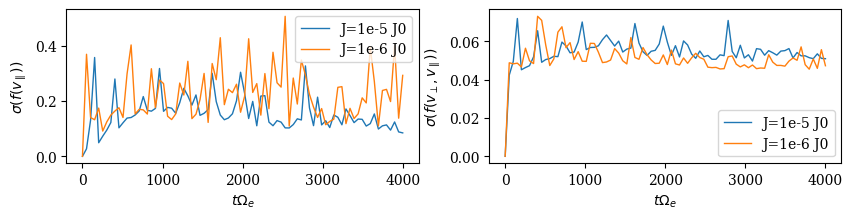

In [102]:
plt.figure(figsize=(10,2))
plt.subplot(121)
xp=np.linspace(0,50*len(phstd1),len(phstd1))
plt.plot(xp,phstd1,label='J=1e-5 J0')
plt.plot(xp,phstd,label='J=1e-6 J0')
plt.legend()
plt.xlabel('$t\Omega_e$')
plt.ylabel('$\sigma (f(v_\parallel))$')
plt.subplot(122)
plt.plot(xp,psdstd1,label='J=1e-5 J0')
plt.plot(xp,psdstd,label='J=1e-6 J0')
plt.legend()
plt.xlabel('$t\Omega_e$')
plt.ylabel('$\sigma (f (v_\perp,v_\parallel))$')
plt.show()

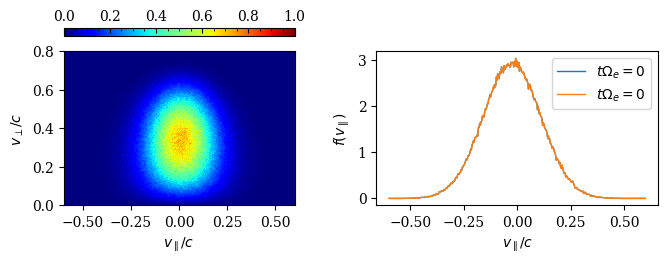

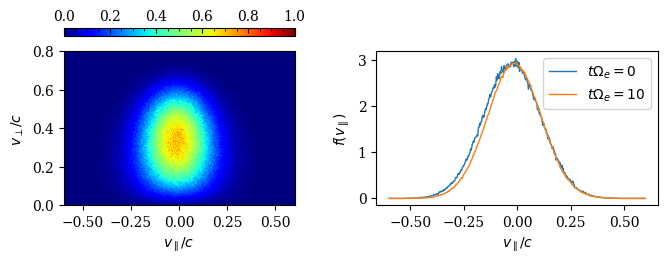

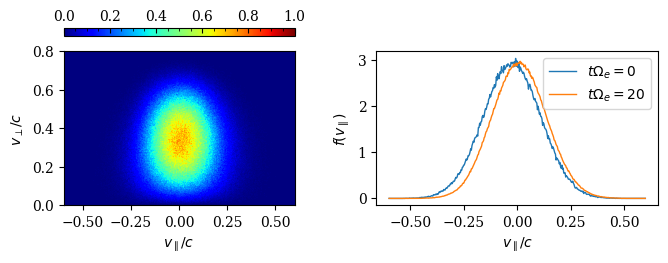

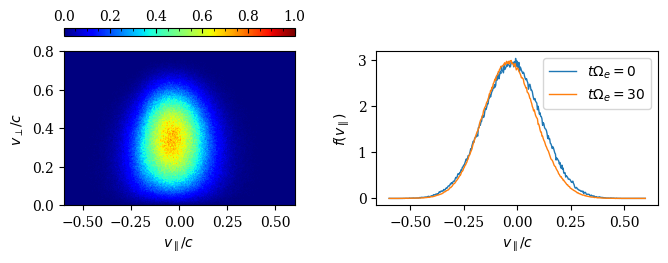

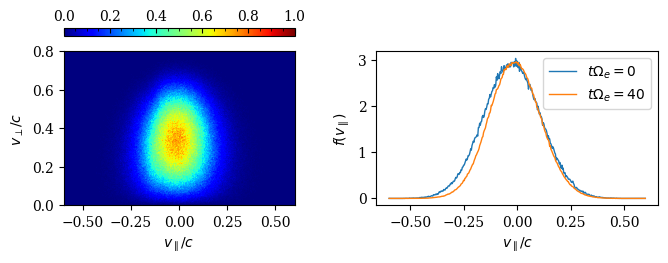

...

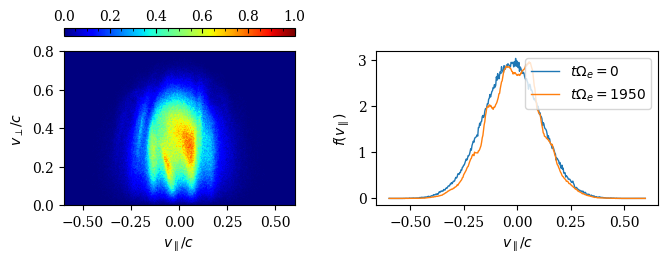

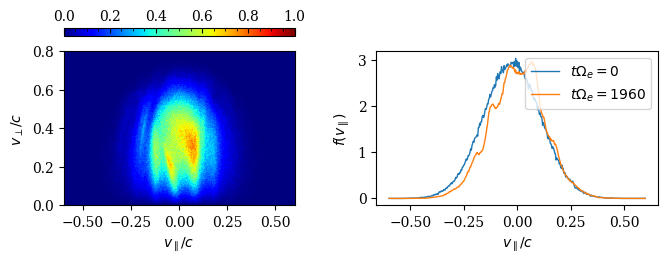

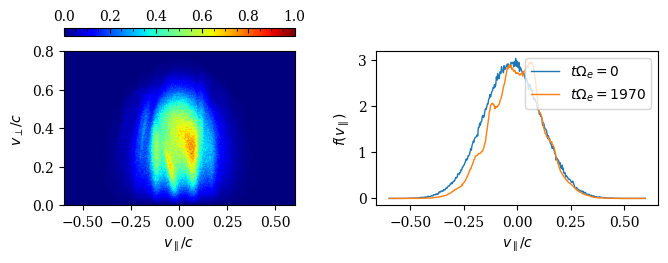

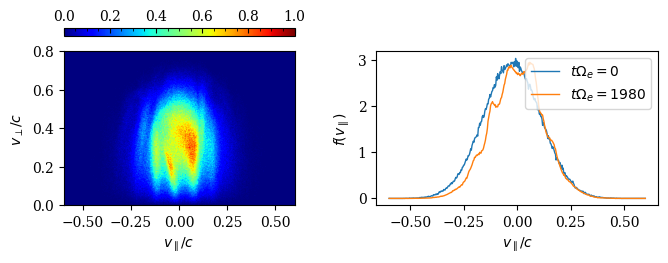

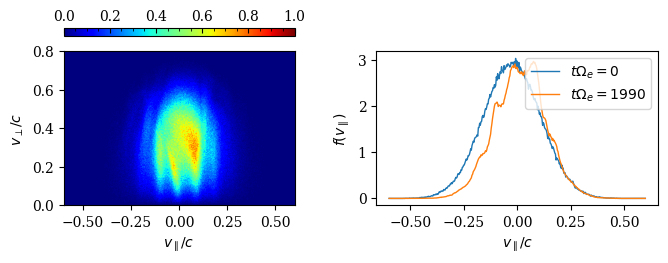

In [88]:
pp_min='0.4'; pp_max='0.5'
std=[];std1=[];rms=[];rms1=[]
for tt in range(0,2000,10):
    plt.figure(figsize=(8,2))
    ph=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/ph_{tt}_{pp_min}_{pp_max}.dat')
    ph0=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/ph_{0}_{pp_min}_{pp_max}.dat')
    psd=np.loadtxt(f'/scratch2/10567/vshankar786/pdata/data/paper/psd_{tt}_{pp_min}_{pp_max}.dat')
    xp=np.linspace(-.6,.6,len(ph0))
    plt.subplot(121)
    im=plt.imshow(psd,origin='lower',cmap='jet',extent=[-.6,.6,0,.8])
    cbar(im,plt.gca(),[.0, 1.1, 1.0, .05],'horizontal')
    plt.ylabel('$v_\perp/c$')
    plt.xlabel('$v_\parallel/c$')
    plt.subplot(122)
    plt.plot(xp,ph0,label=f'$t\Omega_e=0$')
    plt.plot(xp,ph,label=f'$t\Omega_e={tt}$')
    plt.ylabel('$f(v_\parallel)$')
    plt.xlabel('$v_\parallel/c$')
    plt.legend()
    plt.show()